# Finding a Path Between Cities (BFS)

## 1. Is there a path between cities (BFS) ?

Imagine a simple map of flights between cities. Using a dictionary as an adjacency list, each key represents a city, and its value is a list of connected destinations.

In [1]:
from collections import deque

# 1. Represent the graph as a dictionary
flights = {
    "Delhi": ["Mumbai", "Bangalore"],
    "Mumbai": ["Goa"],
    "Bangalore": ["Chennai", "Goa"],
    "Chennai": [],
    "Goa": []
}

# 2. Iterative Breadth-First Search (BFS) to check if a route exists
def can_reach(graph, start, target):
    visited = set()          # Tracks visited cities to avoid infinite loops
    queue = deque([start])   # Queue of cities to explore next

    while queue:
        city = queue.popleft()
        if city == target:
            return True
        
        if city not in visited:
            visited.add(city)
            # Instant O(1) dictionary lookup for connected flights
            queue.extend(graph[city])
            
    return False

print(can_reach(flights, "Delhi", "Goa"))      # Output: True
print(can_reach(flights, "Mumbai", "Chennai")) # Output: False


True
False


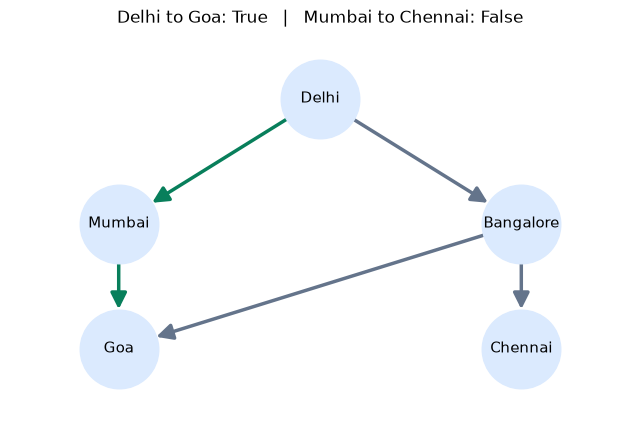

In [2]:
# Lets plot above

import matplotlib.pyplot as plt
import networkx as nx

# Build a directed graph from the same dictionary used by BFS.
graph = nx.DiGraph(flights)

# Fixed positions keep the arrows easy to follow.
positions = {
    "Delhi": (0, 2),
    "Mumbai": (-1.3, 1),
    "Bangalore": (1.3, 1),
    "Goa": (-1.3, 0),
    "Chennai": (1.3, 0),
}

# Highlight one valid route from Delhi to Goa.
route_edges = {("Delhi", "Mumbai"), ("Mumbai", "Goa")}
edge_colors = [
    "#087F5B" if edge in route_edges else "#64748B"
    for edge in graph.edges()
]

fig, ax = plt.subplots(figsize=(8, 5))
nx.draw_networkx(
    graph, positions, ax=ax,
    node_size=3200, node_color="#DBEAFE",
    edge_color=edge_colors, arrowsize=24, width=2.5,
    font_size=11,
)

ax.set_title(
    f"Delhi to Goa: {can_reach(flights, 'Delhi', 'Goa')}   |   "
    f"Mumbai to Chennai: {can_reach(flights, 'Mumbai', 'Chennai')}"
)
ax.margins(0.2)
ax.axis("off")
plt.show()

## 2. Finding the Actual Path (BFS)

Instead of putting single city names into queue, we put lists representing the route taken to reach each city (e.g., ["Delhi", "Mumbai"]). Because BFS explores level-by-level, the first path that reaches the target automatically has the fewest stops.

In [8]:
from collections import deque

flights = {
    "Delhi": ["Mumbai", "Bangalore"],
    "Mumbai": ["Goa"],
    "Bangalore": ["Chennai", "Goa"],
    "Chennai": [],
    "Goa": []
}

def find_path(graph, start, target):
    visited = set()
    queue = deque([[start]])  # Queue stores paths (lists of cities)

    while queue:
        path = queue.popleft()
        city = path[-1]       # Look at the last city in the current path

        if city == target:
            return path       # Return the full route

        if city not in visited:
            visited.add(city)
            for neighbor in graph[city]:
                # Create a new path by appending the neighbor
                queue.append(path + [neighbor])

    return None

print(find_path(flights, "Delhi", "Goa"))
# Output: ['Delhi', 'Mumbai', 'Goa']


['Delhi', 'Mumbai', 'Goa']


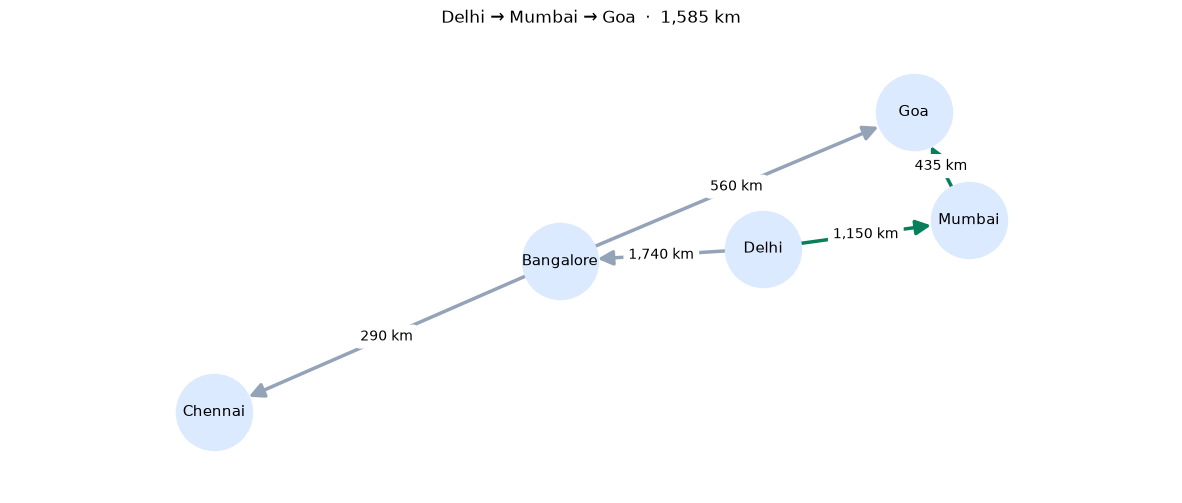

In [9]:
# Now lets plot this
import matplotlib.pyplot as plt
import networkx as nx


def plot_flights(flights, start, target):
    graph = nx.DiGraph()
    graph.add_nodes_from(flights)  # Include cities with no outgoing flights.
    graph.add_weighted_edges_from(
        (city, neighbor, km)
        for city, neighbors in flights.items()
        for neighbor, km in neighbors.items()
    )

    # Include destination-only cities in the dictionary used by Dijkstra.
    adjacency = {city: flights.get(city, {}) for city in graph}
    distance, route = find_shortest_path(adjacency, start, target)
    route_edges = set(zip(route, route[1:])) if route else set()

    # The seed keeps the layout reproducible. Distances are shown as labels.
    positions = nx.spring_layout(graph, seed=42, weight=None)

    fig, ax = plt.subplots(figsize=(15, 6))
    nx.draw_networkx(
        graph, positions, ax=ax,
        node_size=3000, node_color="#DBEAFE", font_size=11,
        arrowsize=22, width=2.5,
        edge_color=[
            "#087F5B" if edge in route_edges else "#94A3B8"
            for edge in graph.edges()
        ],
    )
    nx.draw_networkx_edge_labels(
        graph, positions, ax=ax,
        edge_labels={
            (u, v): f"{km:,} km"
            for u, v, km in graph.edges(data="weight")
        },
        rotate=False,
    )

    if route:
        ax.set_title(f"{' → '.join(route)}  ·  {distance:,} km")
    else:
        ax.set_title(f"No route from {start} to {target}")

    ax.margins(0.2)
    ax.axis("off")
    plt.show()


plot_flights(flights_with_dist, "Delhi", "Goa")


## 3. Finding the Minimum-Distance Path (Dijkstra's Algorithm)

To find the shortest distance, we use a nested dictionary where each neighbor maps to its distance in kilometers. We replace deque with a priority queue (heapq) so the algorithm always explores the path with the lowest total distance first.

In [10]:
import heapq

# Nested dictionary storing flight distances (in km)
flights_with_dist = {
    "Delhi": {"Mumbai": 1150, "Bangalore": 1740},
    "Mumbai": {"Goa": 435},
    "Bangalore": {"Chennai": 290, "Goa": 560},
    "Chennai": {},
    "Goa": {}
}

def find_shortest_path(graph, start, target):
    # Priority queue stores tuples: (total_distance, current_path)
    pq = [(0, [start])]
    visited = set()

    while pq:
        dist, path = heapq.heappop(pq)  # Pop the path with the smallest distance
        city = path[-1]

        if city == target:
            return dist, path           # Return total distance and optimal route

        if city not in visited:
            visited.add(city)
            # Iterate through neighbors and their distances
            for neighbor, weight in graph[city].items():
                if neighbor not in visited:
                    heapq.heappush(pq, (dist + weight, path + [neighbor]))

    return float("inf"), None

distance, route = find_shortest_path(flights_with_dist, "Delhi", "Goa")
print(f"Shortest distance: {distance} km via {route}")
# Output: Shortest distance: 1585 km via ['Delhi', 'Mumbai', 'Goa']


Shortest distance: 1585 km via ['Delhi', 'Mumbai', 'Goa']
